In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('./Time-Series-Analysis-Resources/4-Forecasting_with_regression/data/sales_data.csv')
df.head()

,Years,Sales
0,2001-01-01,139.7
1,2001-02-01,114.3
2,2001-03-01,101.6
3,2001-04-01,152.4
4,2001-05-01,215.9


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Years   72 non-null     str    
 1   Sales   72 non-null     float64
dtypes: float64(1), str(1)
memory usage: 2.0 KB


### Data Preprocessing

In [4]:
df['Years'] = pd.to_datetime(df['Years'])

In [5]:
df.dtypes

Years    datetime64[us]
Sales           float64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Years   72 non-null     datetime64[us]
 1   Sales   72 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.3 KB


In [16]:
df['time'] = np.arange(1,73,1)

In [17]:
df.head()

,Years,Sales,time
0,2001-01-01,139.7,1
1,2001-02-01,114.3,2
2,2001-03-01,101.6,3
3,2001-04-01,152.4,4
4,2001-05-01,215.9,5


In [18]:
df['month_name'] = df['Years'].dt.month_name()

In [20]:
df.head(15)

,Years,Sales,time,month_name
0,2001-01-01,139.7,1,January
1,2001-02-01,114.3,2,February
2,2001-03-01,101.6,3,March
3,2001-04-01,152.4,4,April
4,2001-05-01,215.9,5,May
5,2001-06-01,228.6,6,June
6,2001-07-01,215.9,7,July
7,2001-08-01,190.5,8,August
8,2001-09-01,177.8,9,September
9,2001-10-01,139.7,10,October


In [23]:
# split the data into independent and dependent
# step 1:
# split the data into train (4 years) and test (2 years)
df_train = df[df['time'] <= 48]
df_test = df[df['time'] > 48]

In [24]:
df_train

,Years,Sales,time,month_name
0,2001-01-01,139.7,1,January
1,2001-02-01,114.3,2,February
2,2001-03-01,101.6,3,March
3,2001-04-01,152.4,4,April
4,2001-05-01,215.9,5,May
5,2001-06-01,228.6,6,June
6,2001-07-01,215.9,7,July
7,2001-08-01,190.5,8,August
8,2001-09-01,177.8,9,September
9,2001-10-01,139.7,10,October


In [25]:
df_test

,Years,Sales,time,month_name
48,2005-01-01,266.7,49,January
49,2005-02-01,317.5,50,February
50,2005-03-01,368.3,51,March
51,2005-04-01,431.8,52,April
52,2005-05-01,457.2,53,May
53,2005-06-01,571.5,54,June
54,2005-07-01,546.1,55,July
55,2005-08-01,482.6,56,August
56,2005-09-01,431.8,57,September
57,2005-10-01,406.4,58,October


In [27]:
x_train = df_train[['time']].values
x_train.shape

(48, 1)

In [28]:
y_train = df_train['Sales'].values
y_train.shape

(48,)

In [32]:
x_test = df_test[['time']].values
y_test = df_test['Sales'].values

### Linear Regression with Time
- Trend in the data

In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
model_trend = LinearRegression()
model_trend.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4.41]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,134.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[95.98]


In [31]:
y_fittedvalue = model_trend.predict(x_train)

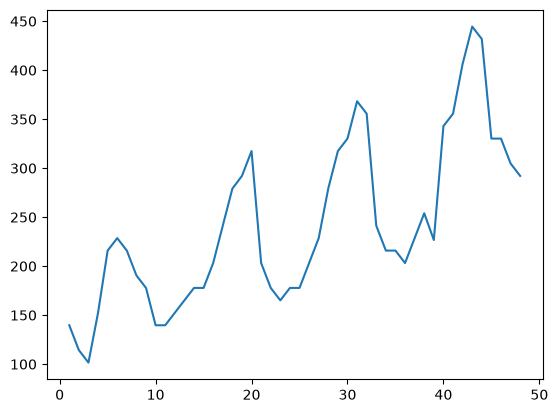

In [33]:
# visualize the data
plt.plot(x_train,y_train)

In [39]:
y_forecast = model_trend.predict(x_test)

*Confidence Interval(CI) - 95% = 1.96*

$CI = \mu \pm ME$

- ME(Margin of Error) --> $ME = z \times SE$
- z = 1.96 for 95% confidence interval
- SE = Standard deviation of the Error

In [41]:
error = y_train - y_fittedvalue
se = error.std()
ME = 1.96 * se

/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_48556/1057934888.py:8: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "-r" (-> color='r'). The keyword argument will take precedence.
  plt.plot(df_test['Years'],y_forecast,'-r',color='red')


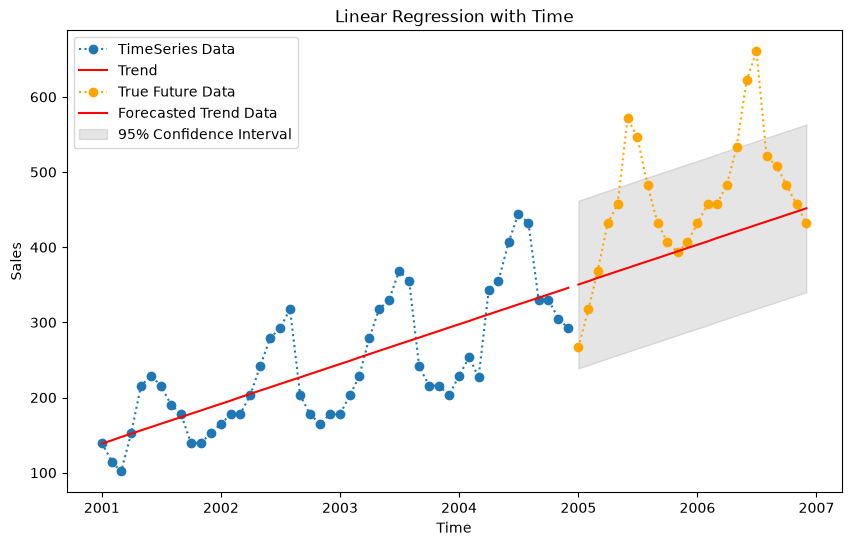

In [44]:
plt.figure(figsize=(10,6))
plt.plot(df_train['Years'],y_train,'o:')
plt.plot(df_train['Years'],y_fittedvalue,'-r')

# Forecasted data

plt.plot(df_test['Years'],y_test,'o:',color='orange')
plt.plot(df_test['Years'],y_forecast,'-r',color='red')

# Margin of error 

ci_plus = y_forecast + ME
ci_minus = y_forecast - ME
plt.fill_between(df_test['Years'], (ci_plus), (ci_minus), color='black', alpha=0.1)

plt.title('Linear Regression with Time')
plt.legend(['TimeSeries Data','Trend', 'True Future Data', 'Forecasted Trend Data', '95% Confidence Interval'])
plt.xlabel('Time')
plt.ylabel('Sales')
plt.show()

In [45]:
df_test

,Years,Sales,time,month_name
48,2005-01-01,266.7,49,January
49,2005-02-01,317.5,50,February
50,2005-03-01,368.3,51,March
51,2005-04-01,431.8,52,April
52,2005-05-01,457.2,53,May
53,2005-06-01,571.5,54,June
54,2005-07-01,546.1,55,July
55,2005-08-01,482.6,56,August
56,2005-09-01,431.8,57,September
57,2005-10-01,406.4,58,October


In [46]:
forecast_mean = model_trend.predict(np.array([[61]]))

In [48]:
print(forecast_mean)
print(forecast_mean-ME,forecast_mean+ME) # TRUE value lies in this interval

[403.28613765]
[291.67694148] [514.89533381]


### Additive Model

In [49]:
df_train.head()

,Years,Sales,time,month_name
0,2001-01-01,139.7,1,January
1,2001-02-01,114.3,2,February
2,2001-03-01,101.6,3,March
3,2001-04-01,152.4,4,April
4,2001-05-01,215.9,5,May


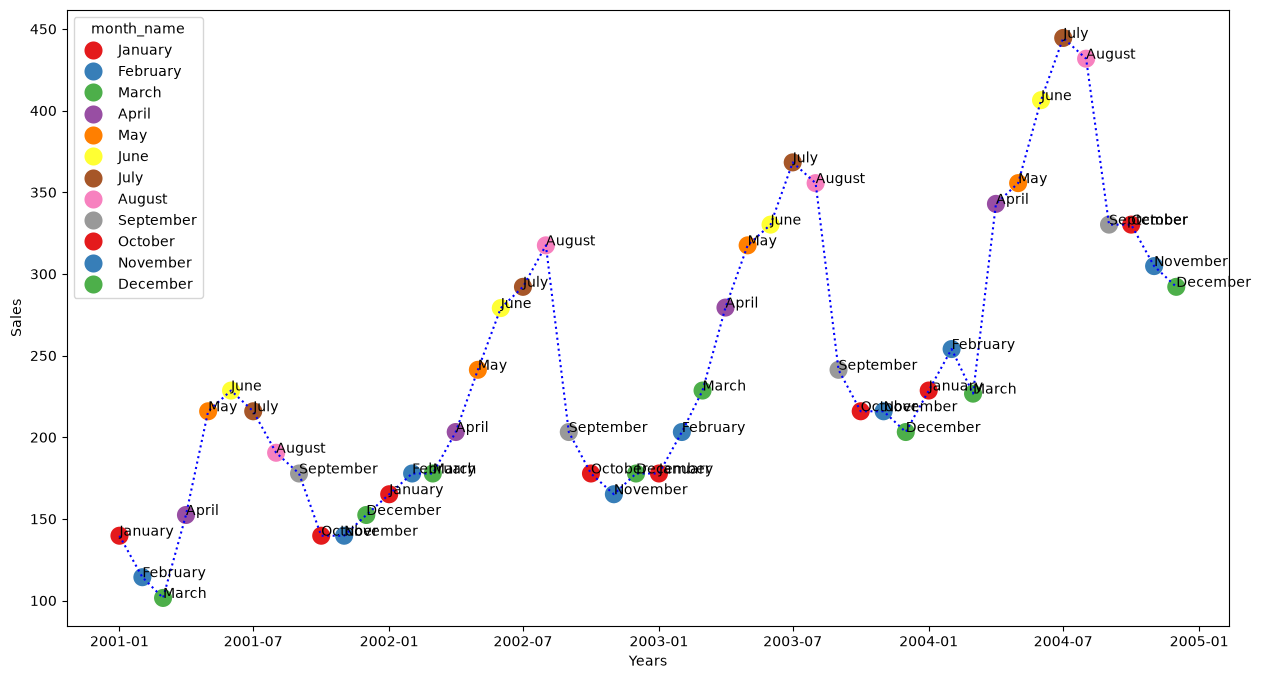

In [55]:
plt.figure(figsize=(15,8))
#plt.scatter(df_train['Years'],df_train['Sales'])
plt.plot(df_train['Years'],df_train['Sales'],'b:')
sns.scatterplot(data=df_train, x='Years', y='Sales', s=200, hue='month_name', palette='Set1')
for i in range(len(df_train)):
    plt.text(df_train['Years'][i],df_train['Sales'][i], df_train['month_name'][i])

seasonality is 12 hence we have to create $n$-1$ dummies that is 11 columns

In [56]:
pd.get_dummies(df_train['month_name']).head()

,April,August,December,February,January,July,June,March,May,November,October,September
0,False,False,False,False,True,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,True,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,True,False,False,False


In [57]:
pd.get_dummies(df_train['month_name'],drop_first=True)

,August,December,February,January,July,June,March,May,November,October,September
0,False,False,False,True,False,False,False,False,False,False,False
1,False,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,True,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,True,False,False,False
5,False,False,False,False,False,True,False,False,False,False,False
6,False,False,False,False,True,False,False,False,False,False,False
7,True,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,True
9,False,False,False,False,False,False,False,False,False,True,False


In [58]:
dum = pd.get_dummies(df_train['month_name'],drop_first=True)
df_train1 = df_train.copy()
df_train1 = pd.concat([df_train1,dum],axis=1)
df_train1.head()

,Years,Sales,time,month_name,August,December,February,January,July,June,March,May,November,October,September
0,2001-01-01,139.7,1,January,False,False,False,True,False,False,False,False,False,False,False
1,2001-02-01,114.3,2,February,False,False,True,False,False,False,False,False,False,False,False
2,2001-03-01,101.6,3,March,False,False,False,False,False,False,True,False,False,False,False
3,2001-04-01,152.4,4,April,False,False,False,False,False,False,False,False,False,False,False
4,2001-05-01,215.9,5,May,False,False,False,False,False,False,False,True,False,False,False


In [59]:
dum = pd.get_dummies(df_test['month_name'],drop_first=True)
df_test1 = df_test.copy()
df_test1 = pd.concat([df_test1,dum],axis=1)
df_test1.head()

,Years,Sales,time,month_name,August,December,February,January,July,June,March,May,November,October,September
48,2005-01-01,266.7,49,January,False,False,False,True,False,False,False,False,False,False,False
49,2005-02-01,317.5,50,February,False,False,True,False,False,False,False,False,False,False,False
50,2005-03-01,368.3,51,March,False,False,False,False,False,False,True,False,False,False,False
51,2005-04-01,431.8,52,April,False,False,False,False,False,False,False,False,False,False,False
52,2005-05-01,457.2,53,May,False,False,False,False,False,False,False,True,False,False,False


In [60]:
# split the data into independent and dependent

cols = ['time', 'August','December','February','January','July','June','March','May','November','October','September']
x_train_add = df_train1[cols].values
x_test_add = df_test1[cols].values
y_train_add = df_train1['Sales'].values
y_test_add = df_test1['Sales'].values

In [62]:
x_train_add.shape, x_test_add.shape, y_train_add.shape, y_test_add.shape

((48, 12), (24, 12), (48,), (24,))

**Additive Model (Linear Regression)**

In [63]:
from sklearn.linear_model import LinearRegression
model_add = LinearRegression()
model_add.fit(x_train_add,y_train_add)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 4.51, 61.33,-74.19,...,-69.68,-55.65,-28.91]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,145.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[95.98, 2. , 2. ,..., 2. , 1.94, 0.58]"


In [64]:
# fitted values
y_fittedvalue_add = model_add.predict(x_train_add)

# forecasted values
y_forecast_add = model_add.predict(x_test_add)

In [65]:
# margin of error
# ME = 1.96*SE

error = y_train_add - y_fittedvalue_add 
SE = error.std()
ME = 1.96 * SE
print('Margin of Error: ', ME)

Margin of Error:  40.351220669612665


/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_48556/1304470686.py:8: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "-r" (-> color='r'). The keyword argument will take precedence.
  plt.plot(df_test1['Years'],y_forecast_add,'-r',color='red')


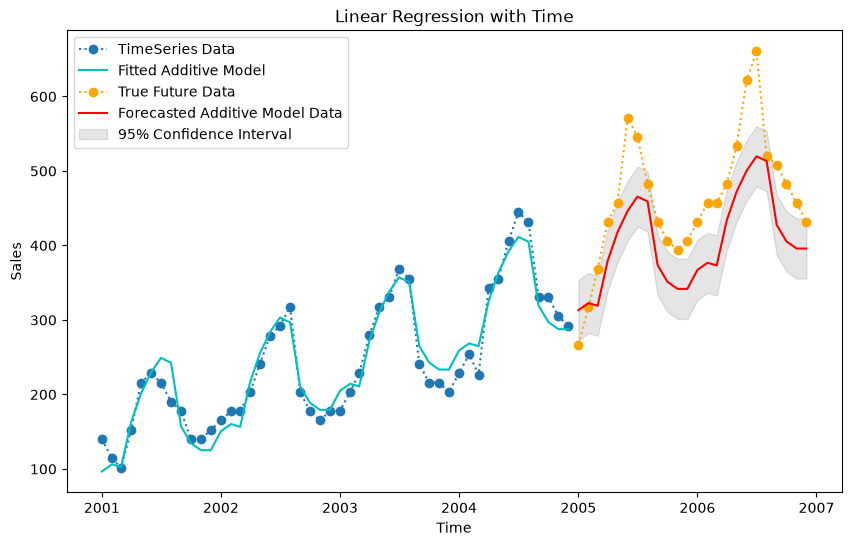

In [68]:
plt.figure(figsize=(10,6))
plt.plot(df_train1['Years'],y_train_add,'o:')
plt.plot(df_train1['Years'],y_fittedvalue_add,'-c')

# Forecasted data

plt.plot(df_test1['Years'],y_test_add,'o:',color='orange')
plt.plot(df_test1['Years'],y_forecast_add,'-r',color='red')

# Margin of error 

ci_plus = y_forecast_add + ME
ci_minus = y_forecast_add - ME
plt.fill_between(df_test1['Years'], (ci_plus), (ci_minus), color='black', alpha=0.1)

plt.title('Linear Regression with Time')
plt.legend(['TimeSeries Data','Fitted Additive Model', 'True Future Data', 'Forecasted Additive Model Data', '95% Confidence Interval'])
plt.xlabel('Time')
plt.ylabel('Sales')
plt.show()


## Multiplicative Model for Forecasting

- **Step-1:** Build the Linear Regression with only time. The output of the model is only Trend **(T)**.

$$
\hat{y}_t = a + b * time
$$

- **Step-2:** Take trend prediction **(T)** and observed or true values which consists of all components trend, seasonality and irregular **(TSI)**.

- **Step-3:** Compute deviation value, and map it as seasonality effect for each prediction.

$$
SI = \frac{TSI}{T}
$$

- **Step-4:** Take average of seasonality value. Use this to make future predictions.

---

**T = Trend, S = Seasonal, I = Irregular**


**Linear Regression with time and sales**

In [69]:
df_train2 = df_train.copy()
df_test2 = df_test.copy()

In [70]:
X_t = df_train2[['time']].values
y_true_mul = df_train2['Sales'].values

X_t.shape,y_true_mul.shape

((48, 1), (48,))

In [71]:
X_t_test = df_test2[['time']].values
y_true_test_mul = df_test2['Sales'].values

X_t_test.shape,y_true_test_mul.shape

((24, 1), (24,))

In [72]:
model_trend_mul = LinearRegression()
model_trend_mul.fit(X_t, y_true_mul)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4.41]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,134.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[95.98]


**Step-2: Take Trend(T) and TSI(True Sample)**

In [73]:
y_fittedvalues_trend = model_trend_mul.predict(X_t)

In [74]:
df_train2['predicted_T'] = y_fittedvalues_trend
df_train2.head()

,Years,Sales,time,month_name,predicted_T
0,2001-01-01,139.7,1,January,138.671939
1,2001-02-01,114.3,2,February,143.082175
2,2001-03-01,101.6,3,March,147.492412
3,2001-04-01,152.4,4,April,151.902649
4,2001-05-01,215.9,5,May,156.312885


**Step-3: Deviation to TSI**

$SI = \frac{TSI}{T}$

In [75]:
df_train2['SI'] = df_train2['Sales']/df_train2['predicted_T']
df_train2.head()

,Years,Sales,time,month_name,predicted_T,SI
0,2001-01-01,139.7,1,January,138.671939,1.007414
1,2001-02-01,114.3,2,February,143.082175,0.798842
2,2001-03-01,101.6,3,March,147.492412,0.688849
3,2001-04-01,152.4,4,April,151.902649,1.003274
4,2001-05-01,215.9,5,May,156.312885,1.381204


**Step-4: Avg Seasonal Deviation**

In [77]:
deviation_season = df_train2[['month_name', 'SI']].groupby('month_name').mean().rename(columns={'SI':'correction_factor'})
deviation_season 

,correction_factor
month_name,
April,1.045770
August,1.289315
December,0.773112
February,0.840934
January,0.841208
July,1.344616
June,1.309853
March,0.804644
May,1.218536


**Step-5: Computing the fitted values**

In [78]:
df_train2 = df_train2.merge(deviation_season,on='month_name')
df_train2.head()

,Years,Sales,time,month_name,predicted_T,SI,correction_factor
0,2001-01-01,139.7,1,January,138.671939,1.007414,0.841208
1,2001-02-01,114.3,2,February,143.082175,0.798842,0.840934
2,2001-03-01,101.6,3,March,147.492412,0.688849,0.804644
3,2001-04-01,152.4,4,April,151.902649,1.003274,1.045770
4,2001-05-01,215.9,5,May,156.312885,1.381204,1.218536


In [79]:
df_train2['Fitted_values'] = df_train2['predicted_T']*df_train2['correction_factor']
df_train2.head()

,Years,Sales,time,month_name,predicted_T,SI,correction_factor,Fitted_values
0,2001-01-01,139.7,1,January,138.671939,1.007414,0.841208,116.651919
1,2001-02-01,114.3,2,February,143.082175,0.798842,0.840934,120.322726
2,2001-03-01,101.6,3,March,147.492412,0.688849,0.804644,118.678920
3,2001-04-01,152.4,4,April,151.902649,1.003274,1.045770,158.855260
4,2001-05-01,215.9,5,May,156.312885,1.381204,1.218536,190.472924


**Forecasting**

In [80]:
ftrend = model_trend_mul.predict(X_t_test)
df_test2['Forecasted_Trend'] = ftrend
df_test2.head()

,Years,Sales,time,month_name,Forecasted_Trend
48,2005-01-01,266.7,49,January,350.363298
49,2005-02-01,317.5,50,February,354.773535
50,2005-03-01,368.3,51,March,359.183771
51,2005-04-01,431.8,52,April,363.594008
52,2005-05-01,457.2,53,May,368.004244


In [81]:
df_test2 = pd.merge(df_test2,deviation_season,on='month_name')
df_test2.head()

,Years,Sales,time,month_name,Forecasted_Trend,correction_factor
0,2005-01-01,266.7,49,January,350.363298,0.841208
1,2005-02-01,317.5,50,February,354.773535,0.840934
2,2005-03-01,368.3,51,March,359.183771,0.804644
3,2005-04-01,431.8,52,April,363.594008,1.045770
4,2005-05-01,457.2,53,May,368.004244,1.218536


In [82]:
df_test2['Forecasted_mul'] = df_test2['Forecasted_Trend']*df_test2['correction_factor']
df_test2.head()

,Years,Sales,time,month_name,Forecasted_Trend,correction_factor,Forecasted_mul
0,2005-01-01,266.7,49,January,350.363298,0.841208,294.728346
1,2005-02-01,317.5,50,February,354.773535,0.840934,298.341276
2,2005-03-01,368.3,51,March,359.183771,0.804644,289.015154
3,2005-04-01,431.8,52,April,363.594008,1.045770,380.235769
4,2005-05-01,457.2,53,May,368.004244,1.218536,448.426528


In [83]:
# margin of error on train data
error = df_train2['Sales'] - df_train2['Fitted_values']
SE = error.std()
ME = 1.96 * SE
ME

np.float64(36.42544715050408)

In [84]:
df_train2.sort_values(by='Years',inplace=True)
df_test2.sort_values(by='Years',inplace=True)

/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_48556/1673233626.py:9: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  plt.plot(df_test2['Years'],df_test2['Forecasted_mul'],'b',color='red')


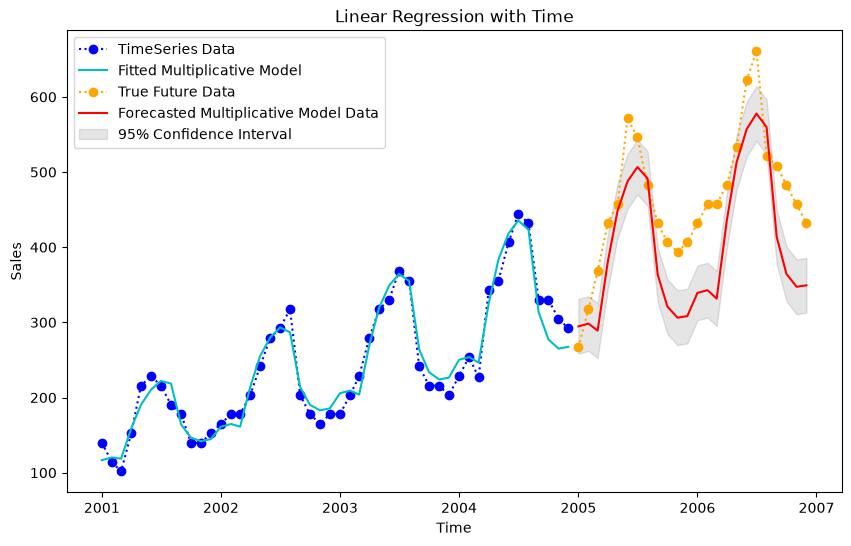

In [85]:
# visualize the data
plt.figure(figsize=(10,6))
plt.plot(df_train2['Years'],df_train2['Sales'],'bo:')
plt.plot(df_train2['Years'],df_train2['Fitted_values'],'c') # fitted values

# Forecasted data

plt.plot(df_test2['Years'],df_test2['Sales'],'o:',color='orange')
plt.plot(df_test2['Years'],df_test2['Forecasted_mul'],'b',color='red')

# Margin of error 

ci_plus = df_test2['Forecasted_mul'] + ME
ci_minus = df_test2['Forecasted_mul'] - ME
plt.fill_between(df_test2['Years'], (ci_plus), (ci_minus), color='black', alpha=0.1)

plt.title('Linear Regression with Time')
plt.legend(['TimeSeries Data','Fitted Multiplicative Model', 'True Future Data', 'Forecasted Multiplicative Model Data', '95% Confidence Interval'])
plt.xlabel('Time')
plt.ylabel('Sales')
plt.show()